In [150]:
from datetime import date
today = date.today()
print('Última corrida el',today)

Última corrida el 2023-01-05


In [151]:
from astropy.io import fits 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.wcs import utils
import astropy.units as u
import astropy.coordinates as coords
from photutils.aperture import CircularAperture,aperture_photometry
from astropy.io import fits
from scipy.stats import norm
from scipy.optimize import curve_fit
from numpy import asarray as ar,exp
import scipy.integrate as integrate
from cycler import cycler
import matplotlib as mpl
import os

In [152]:
# defino parametros generales para los graficos que despues puedo modificar individualmente

styling = {
        'text.usetex' : True,
        'lines.linewidth' : 2,
        'font.family' : 'serif',
        'axes.prop_cycle' : cycler('color', ['#EE6666', '#3388BB', '#9988DD',
                 '#EECC55', '#88BB44', '#FFBBBB']),
        'axes.labelsize' : 35,
        'legend.fontsize' : 30,
        "xtick.labelsize": 30,
        "ytick.labelsize": 30,
        'ytick.major.size' : 5,
        'ytick.minor.size' : 4,
        'xtick.major.size' : 5,
        'xtick.minor.size' : 4,
        'xtick.direction' : 'inout',
        'ytick.direction' : 'inout',  
}

mpl.rcParams.update(styling)

In [153]:
os.chdir("C:/Users/ennis/Documents/Work/2023/pne/m105")

In [154]:
spec = pd.read_csv('m105_aper_phot.csv')

In [155]:
bas = pd.read_csv('m105_dat.cat')

In [156]:
#function to generate an arbitrary wl range of MUSE. Full coverage: (3721)*1.25+4699.625
def wl(N, crpix, crdelt, crval):
    """
    N: numero del slice
    crpix: reference slice de inicio
    crdelt: delta lambda por cada slice
    crval: lambda de referencia/inicio
    """
    return (N+1-crpix)*crdelt + crval

CRPIX1 = 1
CRDEL1 = 1.25
CRVAL1 = float(bas['./../m105.fits'][2])

In [157]:
CRVAL1

4749.56689453125

In [158]:
roth = pd.read_csv('m105_pne.cat',delim_whitespace=True,names=['ra','dec','x','y','flux','cen'])

In [159]:
len(roth['x'])

40

ar = []
for i in range(len(roth['x'])):
    x = roth['x'][i]
    y = roth['y'][i]
    x0 = roth['x']
    y0 = roth['y']

    if(np.any((np.sqrt(np.power((x-x0),2)+np.power((y-y0),2)))<0.5)):
        ind = np.where((np.sqrt(np.power((x-x0),2)+np.power((y-y0),2)))<0.5)
        for j in range(len(ind[0])):
            if(ind[0][j]!=i):
                if(np.all(ind[0][j]!=ar)):
                    ar.append(i)   
            
roth = roth.drop(ar)
roth = roth.reset_index(drop=True)
roth = roth.sort_values(by=['x','y'])
roth = roth.reset_index(drop=True)
len(roth)            

np.savetxt('roth_dropped.txt',roth)

In [160]:
#flux and eflux values will correstond to 
n = 24 #star id-1 (-1 because of python)
flux = spec.values[n, 3::2]
eflux = spec.values[n, 4::2]
slices_to_extract = np.arange(len(flux))
w = wl(N=slices_to_extract, crpix=CRPIX1, crdelt=CRDEL1, crval=CRVAL1) #creates the array of wl to use with the extracted spectrum
min(w)

4749.56689453125

In [161]:
CRVAL1

4749.56689453125

In [162]:
w = w/(1+0.003026)
min(w)

4735.2380641491345

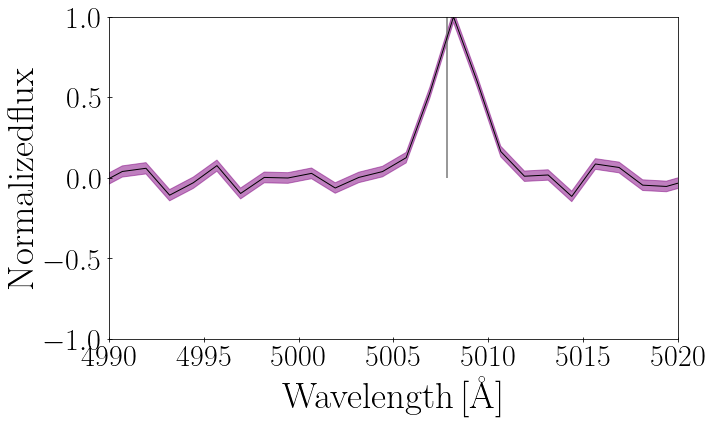

In [163]:
plt.figure(figsize=(10,6))

shift = 0.0 #pix/AA

plt.xlim(4990, 5020)
#plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
plt.vlines(x=5007.8, ymin=0, ymax=1.1, color='gray', alpha=0.8)

plt.ylim(-1, 1)
plt.ylabel(r'${\rm Normalized flux}$', size=37)
plt.xlabel(r'${\rm Wavelength\,[\AA]}$', size=37)

plt.tight_layout()

#plt.savefig('full.png')


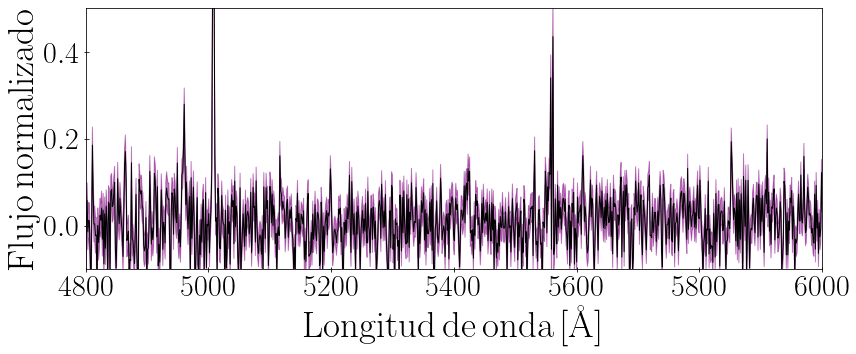

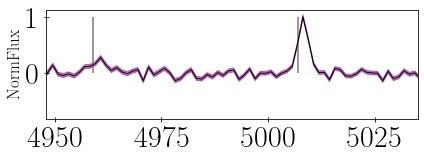

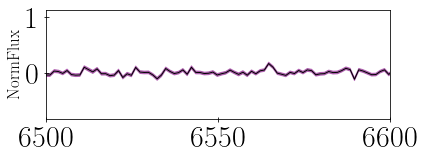

In [164]:
plt.figure(figsize=(12,5))

shift = 0. #pix/AA

plt.xlim(4800, 6000)
#plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
plt.vlines(x=5008, ymin=1.0, ymax=1.1, color='gray', alpha=0.8)

plt.ylim(-0.1, 0.5)
plt.ylabel(r'${\rm Flujo\,normalizado}$', size=37)
plt.xlabel(r'${\rm Longitud\,de\,onda\,[\AA]}$', size=37)

plt.tight_layout()

#plt.savefig('short.png')

plt.show()

#center on OIII
shift = 0. #pix/AA
plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
plt.vlines(x=5007, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
plt.vlines(x=4959, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)

#plt.savefig('spectrfull.png')

plt.xlim(4948, 5035)
#plt.ylim(0, 1000)
plt.ylabel(r'${\rm Norm Flux}$', size=17)
plt.ylabel(r'${\rm Norm Flux}$', size=17)

plt.tight_layout()
#plt.savefig('spectr.png')
plt.show()

# center on Halpha
shift = 0. #pix/AA
plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
#plt.vlines(x=6564.61, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
plt.xlim(6500, 6600)
#plt.ylim(0.3, 0.7)
plt.ylabel(r'${\rm Norm Flux}$', size=17)
plt.ylabel(r'${\rm Norm Flux}$', size=17)

plt.tight_layout()
#plt.savefig('spectr_h.png')

plt.show()



In [165]:
roth['cen'] = roth['cen']/(1+0.003026)

In [166]:
len(spec)

40

In [176]:
mag = np.zeros(len(spec['id']))
flu = np.zeros(len(spec['id']))
m_o = np.zeros(len(spec['id']))
flu2 = np.zeros(len(spec['id']))
flu3 = np.zeros(len(spec['id']))

for i in range(len(spec['id'])):
    
    flux = spec.values[i, 3::2]
    
    
    h_al = 6564.61

    ind = np.where(np.abs((w-h_al))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    h_fil = flux[start:end]

    m_h = np.sum(h_fil,axis=0)


    oiii = 5008

    ind = np.where(np.abs((w-roth['cen'][i]))<0.625)

    start = ind[0][0]-3
    end = ind[0][0]+3
    o_fil = flux[start:end]
    m_o[i] = np.sum(o_fil,axis=0)

    nii = 6585.27

    ind = np.where(np.abs((w-nii))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    n_fil = flux[start:end]

    m_n = np.sum(n_fil,axis=0)
    
    sii = 6716

    ind = np.where(np.abs((w-sii))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    s_fil = flux[start:end]

    m_s = np.sum(s_fil,axis=0)
    
    sii2 = 6731

    ind = np.where(np.abs((w-sii2))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    s_fil2 = flux[start:end]

    m_s2 = np.sum(s_fil2,axis=0)
    
    if(m_o[i]>0):
        mag[i] = -2.5*np.log10(m_o[i]*np.power(10.0,-20))-13.74
        flu[i] = m_o[i]/(m_h+m_n)
        flu2[i] = m_h/m_n
        flu3[i] = m_h/(m_s+m_s2)
    else:
        mag[i] = 99
        flu[i] = 0
        
print(mag)

[26.23726696 27.64165107 27.42685144 26.38988172 27.5830206  26.72858212
 26.63828056 26.85804919 26.97696205 26.73262495 27.05467738 27.6001861
 27.1261192  26.60256603 28.11605458 26.40746478 26.61901086 26.61428346
 25.64523234 28.98339841 25.30282376 26.38438096 27.49304566 25.91166714
 26.27716899 27.07010011 26.82584194 26.32316549 25.96273975 27.06048746
 26.39010339 28.35558947 26.71225334 26.18916312 28.13123296 27.47283486
 26.50516823 26.74501562 27.61282236 27.0796305 ]


In [177]:
new = np.asarray([roth['x'],roth['y'],roth['ra'],roth['dec'],roth['cen'],mag,m_o])
new = new.transpose()
#np.savetxt('catalogo.txt',new)

In [178]:
condition = np.log10(flu)>(-0.37*((mag)-(30.56))-1.16)
condition2 = flu<4
mag2 = mag[condition&condition2]

c:\users\ennis\anaconda3\envs\py36\lib\site-packages\ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in log10
  """Entry point for launching an IPython kernel.


In [179]:
pne = np.asarray([roth['x'][condition&condition2],roth['y'][condition&condition2],roth['ra'][condition&condition2],roth['dec'][condition&condition2],roth['cen'][condition&condition2],mag[condition&condition2],m_o[condition&condition2]])
pne = pne.transpose()
#np.savetxt('pne.txt',pne)

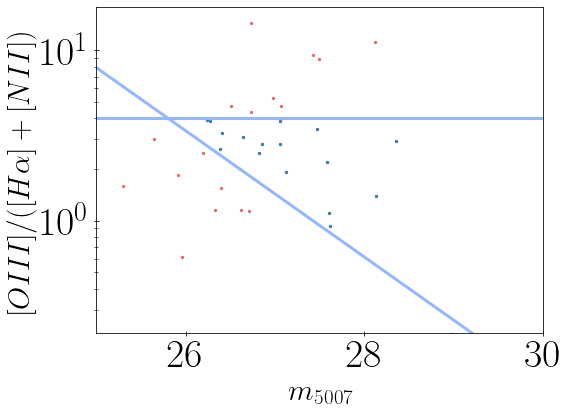

In [191]:
fig,ax = plt.subplots(figsize=(8,6))

plt.scatter(mag,flu,s=5)
magarr = np.arange(20,35)

plt.scatter(mag[condition&condition2],flu[condition&condition2],s=5)

y = np.power(10,-0.37*((magarr)-(30.56))-1.16)
plt.yscale('log',base=10)
#plt.vlines(31.2-4.5,0,10)
plt.plot(magarr,y,color='#95b7ff',linewidth=3)
plt.hlines(4,20,30,color='#95b7ff',linewidth=3)
plt.xlim(25,30)
plt.ylim(0.22,18)

plt.xticks(fontsize=40)
plt.yticks(fontsize=40)
plt.ylabel(r'$[OIII]/([H\alpha]+[NII])$',fontsize=30)
plt.xlabel('$m_{5007}$',fontsize=30)
plt.savefig('diagnostic.png',bbox_inches='tight')

In [192]:
len(pne)

17

c:\users\ennis\anaconda3\envs\py36\lib\site-packages\ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in log10
  This is separate from the ipykernel package so we can avoid doing imports until


Text(0.5, 0, '$[H\\alpha]/[SII]$')

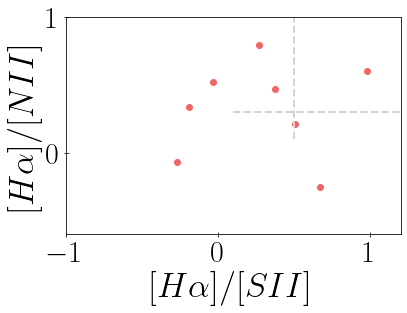

In [193]:
fig,ax = plt.subplots(figsize=(6,4))

plt.scatter(np.log10(flu3[condition&condition2]),np.log10(flu2[condition&condition2]))


#y = np.power(10,-0.37*((magarr)-(31))-1.16)
#plt.yscale('log',base=10)
#plt.xscale('log',base=10)
plt.hlines(0.3,0.1,10,linestyle='dashed',color='lightgrey')

plt.vlines(0.5,0.1,10,linestyle='dashed',color='lightgrey')
#plt.plot(flu2,flu3,color='#95b7ff')
#plt.hlines(4,26,30,color='#95b7ff')
plt.xlim(-1,1.2)
plt.ylim(-0.6,1)

plt.ylabel(r'$[H\alpha]/[NII]$')
plt.xlabel(r'$[H\alpha]/[SII]$')
#plt.savefig('diagnostic2.png',bbox_inches='tight')

In [198]:
from astropy.io import fits

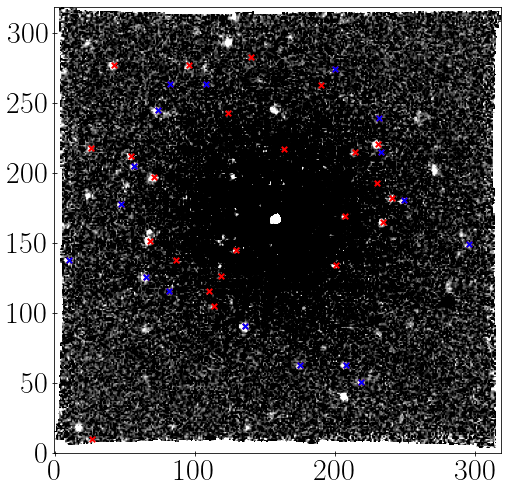

In [231]:
fig,ax = plt.subplots(figsize=(8,15))
hdu = fits.open('m105-5_slinan.fits')
image_data = hdu[1].data

plt.imshow(image_data, cmap='gray',vmin=-10,vmax=100,origin='lower')
#plt.colorbar()
plt.scatter(roth['x'],roth['y'],s=30,c='red',marker='x')
plt.scatter(pne[:,0],pne[:,1],c='b',s=30,marker='x')
plt.savefig('gal_sources.png')

In [195]:
min(mag2)

26.237266962909146

In [125]:
binw = np.arange(27.11,30.61,0.5)

def pnlf(x,c,b):
    return c*exp(-b*x)*(1-exp(3*((26.3)-x)))

def PNLF_analytic(m5007, mag, c1):
    return c1*np.exp(-0.302*mag)*np.exp(0.302*m5007)*(1.- np.exp(3*(-4.51 + mag - m5007)))


histp = list(np.histogram(mag2,bins=binw))

mids = 0.5*(binw[1:] + binw[:-1])

popt,pcov = curve_fit(PNLF_analytic,mids,histp[0],p0=[31,0.6])
x0 = np.arange(26,27.5,0.1)
popt

array([31.75446992,  0.75446973])

In [126]:
binw = np.arange(27.035-0.35/2,29.485+0.35/2,0.35)
histp = list(np.histogram(mag2,bins=binw))
mids = 0.5*(binw[1:] + binw[:-1])
print(histp[0])

[5 0 0 1 1 0 0 0]


In [127]:
histp

[array([5, 0, 0, 1, 1, 0, 0, 0], dtype=int64),
 array([26.86, 27.21, 27.56, 27.91, 28.26, 28.61, 28.96, 29.31, 29.66])]

In [39]:
compl = pd.read_csv('res_mg4',delim_whitespace=True)
len(compl)
compl['magnitude'] = compl['magnitude'] + 4.86

In [27]:
compl

,magnitude,detection_completeness,counts_simulated
0,27.035,0.920000,4
1,27.385,0.916667,12
2,27.735,0.909091,11
3,28.085,0.833333,18
4,28.435,0.714286,14
5,28.785,0.418182,22
6,29.135,0.300000,20
7,29.485,0.230769,13


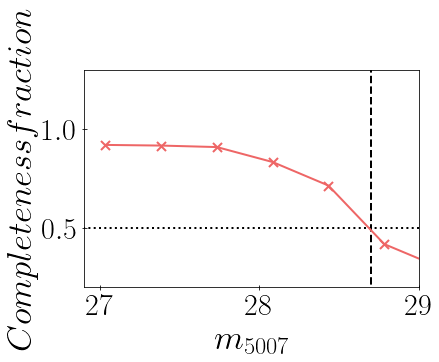

In [28]:
from scipy import interpolate
f1 = interpolate.interp1d(compl['magnitude'],compl['detection_completeness'])
plt.xlim(26.9,29)
plt.ylim(0.2,1.3)
plt.scatter(compl['magnitude'],compl['detection_completeness'],marker='x',s=82)
plt.xlabel('$m_{5007}$')
plt.ylabel('$Completeness fraction$')
plt.plot(compl['magnitude'],f1(compl['magnitude']))
plt.hlines(0.5,25,30,linestyles='dotted',color='black')
plt.vlines(28.7,0,2,linestyles='dashed',color='black')
#plt.savefig('completeness.png',bbox_inches='tight')

In [140]:
##### lo que hable con fuyan
##### la magnitud que tengo yo de las nebulosas es la total de integrar toda la linea a traves de no se 
#### cuantas slices entonces no me sirve usar eso de zeropoint
#### tengo que ver cuanto es la magnitud en una sola slice y usar eso para la lista de input
# y para el zeropoint de mkobjects
### tengo que ver como se relaciona la cantidad de cuentas en la slice mas chiquita con la cantidad total
### asi puedo relacionar la magnitud de una slice sola con la que obtengo al final con el -13.74

In [141]:
compl[0:8]

,magnitude,detection_completeness,counts_simulated
0,27.035,0.920000,4
1,27.385,0.916667,12
2,27.735,0.909091,11
3,28.085,0.833333,18
4,28.435,0.714286,14
5,28.785,0.418182,22
6,29.135,0.300000,20
7,29.485,0.230769,13


In [142]:
histp

[array([0, 2, 2, 2, 1, 3, 5, 0], dtype=int64),
 array([26.86, 27.21, 27.56, 27.91, 28.26, 28.61, 28.96, 29.31, 29.66])]

In [143]:
import lmfit
from lmfit import Model

In [144]:
def gaussian(x, amp, cen, wid):
    return amp * exp(-(x-cen)**2 / wid)

gmodel = Model(gaussian)
x = np.linspace(-10, 10, 101)
y = gaussian(x, 2.33, 0.21, 1.51) 
result = gmodel.fit(y, x=x, cen=0.5, amp=10, wid=2.0)


In [34]:
mids,corr

NameError: name 'corr' is not defined

In [128]:
binw = np.arange(27.035,29.485,0.35)

def PNLF_analytic(m5007, mag, c1):
    return c1*np.exp(-0.302*mag)*np.exp(0.302*m5007)*(1.- np.exp(3*(-4.51 + mag - m5007)))

def PNLF_analytic2(m5007, c1, c2):
    return c1*np.exp(-c2*31.44)*np.exp(c2*m5007)*(1.- np.exp(3*(-4.51 + 31.44 - m5007)))


histp2 = list(np.histogram(mag2,bins=binw))
corr = histp[0]/compl['detection_completeness']
mids2 = 0.5*(binw[1:] +binw[:-1])
condition = mids < 28.7
popt,pcov = curve_fit(PNLF_analytic,mids[condition],corr[condition],p0=[31,0.8])
popt2,pcov2 = curve_fit(PNLF_analytic2,mids[condition],corr[condition],bounds=([0,0],[100,10]))

x0 = np.arange(26,27.5,0.1)
print(popt,popt2)

NameError: name 'compl' is not defined

In [91]:
#corr[4] = 2.5
corr

0     0.000000
1     2.181818
2     2.200000
3     2.400000
4     2.500000
5     7.173913
6    16.666667
7     0.000000
Name: detection_completeness, dtype: float64

In [113]:
pnlfv = Model(PNLF_analytic2)
pnlfs = Model(PNLF_analytic)
print(f'parameter names: {pnlfv.param_names}')
print(f'independent variables: {pnlfv.independent_vars}')
condition = (mids < 29) 

x = mids[condition]
y = corr[condition]
x,y

parameter names: ['c1', 'c2']
independent variables: ['m5007']


(array([27.035, 27.385, 27.735, 28.085, 28.435, 28.785]),
 0    0.000000
 1    2.181818
 2    2.200000
 3    2.400000
 4    1.400000
 5    7.173913
 Name: detection_completeness, dtype: float64)

In [114]:
result = pnlfv.fit(y, m5007=x, c1=10, c2=0.4)
#results = pnlfs.fit(y, m5007=x, c1=0.4)
print(result.fit_report())
#print(results.fit_report())

[[Model]]
    Model(PNLF_analytic2)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 62
    # data points      = 6
    # variables        = 2
    chi-square         = 9.86663229
    reduced chi-square = 2.46665807
    Akaike info crit   = 6.98439472
    Bayesian info crit = 6.56791366
[[Variables]]
    c1:  378.927393 +/- 830.256381 (219.11%) (init = 10)
    c2:  1.50868982 +/- 0.75834727 (50.27%) (init = 0.4)
[[Correlations]] (unreported correlations are < 0.100)
    C(c1, c2) = 0.996


In [115]:
corr[condition]

0    0.000000
1    2.181818
2    2.200000
3    2.400000
4    1.400000
5    7.173913
Name: detection_completeness, dtype: float64

In [116]:
compl['detection_completeness']

0    0.920000
1    0.916667
2    0.909091
3    0.833333
4    0.714286
5    0.418182
6    0.300000
7    0.230769
Name: detection_completeness, dtype: float64

In [117]:
class Ly_alpha(object):
    """
    This is the luminosity function of Ly-alpha emitters at z = 3.1, scaled to our survey area
    and with fluxes converted to F_5007 / m_5007. This function can be interpolated in order
    to determine the number of Ly-alpha emitters per magnitude bin of the PNLF.
     """
    def __init__(self, L_star = 10**42.66, L_range = 10**np.linspace(41, 44, 40),
        alpha = -1.36, phi0 = 1.28e-3, area_conversion = 8.666666666666e58,
        frac_area = 0.75, area = 1.686e5, bin_width = 0.2):
        self.L_star = L_star
        self.L_range = L_range
        self.alpha = alpha
        self.phi0 = phi0
        self.area_conversion = area_conversion
        self.frac_area = frac_area
        self.area = area #u.Mpc
        self.bin_width = 0.2

    def Schechter(self, x):
        return self.phi0*x**self.alpha*np.exp(-x)*self.frac_area*self.area

    @property
    def logN(self):
        return np.log10(self.Schechter(self.L_star/self.L_range))

    def to_m5007(self, flux):
        return -2.5*np.log10(flux) - 13.74

    @property
    def m_range(self):
        return self.to_m5007(self.L_range/self.area_conversion)[::-1]



In [118]:
ly = Ly_alpha(1)

In [119]:
class PNLF(object):
    """
    This function calculates the PNLF given magnitude data of PNe (organised in the PN tracers class)
    In case color or detection completeness are not known, put 1
    """
    def __init__(self, PNe, galaxy, Ly_alpha, mag_bins, color_completeness,
        detection_completeness, Ntot = 15, normalized = True):
        self.PNe = PNe
        self.galaxy = galaxy
        self.Ly_alpha = Ly_alpha
        self.mag_bins = mag_bins
        self.color_completeness = color_completeness
        self.detection_completeness = detection_completeness
        self.Nsample = len(self.PNe.mag)
        self.normalized = normalized
        self.Ntot = Ntot
        self.r = 1.#self.Nsample/float(self.Ntot)


    @property
    def N_PN(self):
        N_PN, bin_edges = np.histogram(self.PNe.mag, self.mag_bins)
        return N_PN

    @property
    def bin_edges(self):
        N_PN, bin_edges = np.histogram(self.PNe.mag, self.mag_bins)
        return bin_edges

    @property
    def bin_centers(self):
        return  0.5*(self.bin_edges[1:] + self.bin_edges[:-1])
        

    @property
    def bin_width(self):
        return self.bin_edges[1:] - self.bin_edges[:-1]

    @property
    def N_Ly(self):
        interp = interpolate.interp1d(self.Ly_alpha.m_range, self.Ly_alpha.logN)
        return 10**(interp(self.bin_centers))*self.bin_width

    @property
    def N_corr(self):
        return self.N_PN/self.bin_width/self.color_completeness/self.detection_completeness

    @property
    def N_PN_Lya(self):
        Ly_contr = self.r*self.N_Ly
        if self.normalized == True:
            return (self.N_corr - Ly_contr)/self.Nsample
        else:
            return self.N_corr - Ly_contr

    @property
    def error(self):
        err_poiss= self.N_PN/(self.bin_width*self.color_completeness*self.detection_completeness)**2
        err_Ly =  self.bin_width*self.Ly_alpha.bin_width*self.r*self.N_Ly
        if self.normalized == True:
            return np.sqrt(err_poiss )/self.Nsample
        else:
            return np.sqrt(err_poiss )

    @property
    def LF(self):
        return np.log10(self.N_PN)

    @property
    def log_err(self):
        low = np.log10(self.N_PN) - np.log10(self.N_PN - self.error)
        high = np.log10(self.N_PN + self.error) - np.log10(self.N_PN)
        return [low, high]

    
class galaxy(object):
    def __init__(self, RA_center, dec_center, PA, ell, r_ell, distance):
        self.RA_center = coords.Angle(RA_center, unit = u.hourangle)
        self.dec_center = coords.Angle(dec_center, unit = u.deg)
        self.PA = u.Quantity(0.5*np.pi, u.radian) - u.Quantity(PA, u.radian)
        self.ell = ell
        self.r_ell = u.Quantity(r_ell, unit = u.arcsecond)
        self.distance = distance

    @property
    def distance_modulus(self):
        return 5.*np.log10(self.distance) - 5.

def area_ellipse(ell, a_arr):
    A = [np.pi*(1.-ell)*(a_arr[0]**2)]
    for i in range(1,len(a_arr)):
        A.append(np.pi*(1.-ell)*(a_arr[i]**2 - a_arr[i-1]**2))
    return np.array(A)

class PNe(object):
    def __init__(self, ID, RA, dec, mag, vel, vel_err, galaxy):
        self.ID = ID
        self.RA = coords.Angle(RA, unit = u.hourangle)
        self.dec = coords.Angle(dec, unit = u.deg)
        self.mag = mag
        self.vel = vel
        self.vel_err = vel_err
        self.galaxy = galaxy

    @property
    def RA_shifted(self):
        return self.RA - self.galaxy.RA_center

    @property
    def dec_shifted(self):
        return self.dec - self.galaxy.dec_center

    @property
    def r_major(self):
# RA and dec are already shifted wrt center coordinates
# RA, dec --> astropy angles
# output in degrees
        q = 1. - self.galaxy.ell
        x = self.RA_shifted.degree * np.cos(self.galaxy.PA) - self.dec_shifted.degree
        y = self.RA_shifted.degree * np.sin(self.galaxy.PA) + self.dec_shifted.degree 
        return np.sqrt(x**2 + y**2/q**2)

    @property
    def radius(self):
        return np.sqrt(self.RA_shifted.degree**2 + self.dec_shifted.degree**2)

    @property
    def angle(self):
        x = self.RA_shifted.degree * np.cos(self.galaxy.PA) - self.dec_shifted.degree 
        y = self.RA_shifted.degree * np.sin(self.galaxy.PA) + self.dec_shifted.degree 
        angl = coords.Angle(np.arctan2(y,x), unit = u.rad)
        return angl

In [120]:
NGC1387 = galaxy(RA_center = 54.237750 * u.deg, dec_center = -35.506639 ,
                PA = 60 * u.deg, ell = 0.3, r_ell = 10, distance = 19.1e3)

In [121]:
ID_number = list(range(len(pne)))
RAJ2000 = pne[:,2]
decJ2000 = pne[:,3]
magOIII = pne[:,5]
velfake = pne[:,4]

In [122]:
PNe = PNe(ID = ID_number, RA = RAJ2000 * u.deg, dec = decJ2000 * u.deg, mag = magOIII, vel = velfake, galaxy = NGC1387, vel_err= velfake)

In [123]:
obj_pn = PNLF(PNe, galaxy, ly, histp[1], 1, compl['detection_completeness'], Ntot = 15, normalized = True)

In [226]:
errores = obj_pn.error
errores[0] = 0.1
corr[4] = 2.5
corr[0] = 0.0

In [227]:
condition = (mids < 28.7) 
popt2,pcov2 = curve_fit(PNLF_analytic2,mids[condition],corr[condition],bounds=([0,0.1],[200,0.9]),sigma=errores[0:5])
popt2

array([11.61468987,  0.47645036])

In [247]:
corr

0     0.000000
1     2.181818
2     2.200000
3     2.400000
4     2.500000
5     7.173913
6    16.666667
7     0.000000
Name: detection_completeness, dtype: float64

In [209]:
popt2[0] = 51
popt2[1] = 0.8
#popt2[2] = 1.5


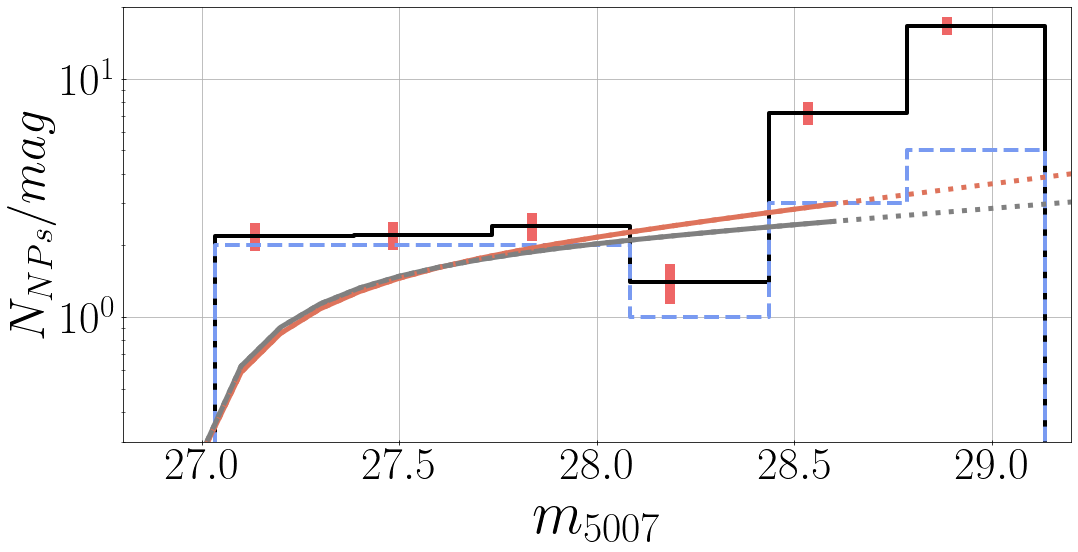

In [249]:

fig,ax = plt.subplots(figsize=(17,8))
plt.grid(True)
plt.step(mids,histp[0]/compl['detection_completeness'],color='black',linewidth=4)
plt.step(mids,histp[0],color='#799af1',linestyle='dashed',linewidth=4)

#plt.hist(mag,18,color='#799af1',density=True)
plt.xlim(26.8,29.2)
plt.xlabel('$m_{5007}$',fontsize=60)
plt.ylabel('$N_{NPs}/mag$',fontsize=50)
plt.ylim(0.3,20)
x0 = np.arange(26,28.7,0.1)
plt.plot(x0,PNLF_analytic2(x0,*popt2),'r-',label='fit',c='#de735b',linewidth=5)
plt.plot(x0,PNLF_analytic(x0,*popt),'r-',label='fit',c='grey',linewidth=5)
plt.yticks(fontsize=45)
plt.xticks(fontsize=45)

plt.errorbar((mids-0.25), histp[0]/compl['detection_completeness'], yerr = errores, fmt = 'none', linewidth=10)

x0 = np.arange(27,29.5,0.1)
plt.plot(x0,PNLF_analytic2(x0,*popt2),'r:',label='fit',c='#de735b',linewidth=5)
plt.plot(x0,PNLF_analytic(x0,*popt),'r:',label='fit',c='grey',linewidth=5)

plt.yscale('log')

plt.savefig('pnlf2.png',bbox_inches='tight')

In [238]:
histp[0]

array([0, 2, 2, 2, 1, 3, 5, 0], dtype=int64)

In [52]:
magr = -2.5*np.log10(roth['flux']*np.power(10.0,-20))-13.74

In [53]:
def idem(x, b):
    return x+b

popt,pcov = curve_fit(idem,mag[mag<99],magr[mag<99],p0=[15])
x0 = np.arange(25,32,0.1)
popt

array([0.10273504])

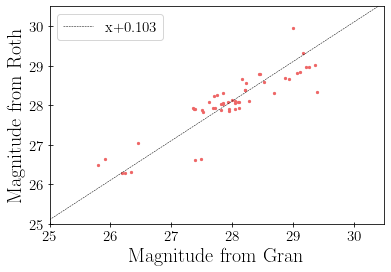

In [54]:
plt.ylim(25,30.5)
plt.xlim(25,30.5)
plt.scatter(mag,magr,s=5)

plt.plot(x0,idem(x0,*popt),'k--',linewidth=0.5,label='x+0.103')
plt.legend()
plt.xlabel('Magnitude from Gran')
plt.ylabel('Magnitude from Roth')
plt.savefig('flux_comparison.pdf')

plt.savefig('mag_comp.png',bbox_inches='tight')